# Import

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import FortranFile
import smplotlib
from hmf import MassFunction
from astropy.cosmology import FlatLambdaCDM, Planck18
import pandas as pd


findfont: Failed to find font weight normal, now using 500.


# Path 

In [2]:
root = Path("..").resolve()
tree_dir = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine")
results = root / "Results_dex"
zgrid = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
print(len(list(results.glob("merger_tree_out_*"))), "files")


600 files


In [3]:
Om, Ob, Ode, h = 0.30966, 0.05, 0.68885, 0.70
G, Msun, Mpc = 6.67e-8, 2.0e33, 3.086e24
a_grain, rho_grain, spin = 5.0e-6, 2.25, 0.04
lam_A, c_A = 1500.0, 2.9979e18
H0_cgs = h * 1e7 / Mpc
cosmo = FlatLambdaCDM(H0=Planck18.H0.value, Om0=Om, Ob0=Ob, Tcmb0=2.7)

mass_function = MassFunction(z=4.5, cosmo_model=cosmo,
                            sigma_8=0.811, n=0.965,
                            hmf_model="ST", transfer_model="EH",
                            Mmin=7, Mmax=15, dlog10m=0.01,
                            )

logM_st = np.log10(mass_function.m * h)
phi_st = mass_function.dndlog10m * h**3
dlogM_tree = 6.0 / 600.0
logM = []
weight = []


In [4]:
with FortranFile(zgrid, "r") as f:
    _ = f.read_ints(np.int32)
    redshifts = f.read_reals(np.float64)

def single_input_tree(p):
    with FortranFile(p, "r") as f:
        _ = int(f.read_ints(np.int32)[0])
        redshift_index_of_halos = f.read_ints(np.int32)
        mass_halos = f.read_reals(np.float64)
        parent = f.read_ints(np.int32)
        _ = f.read_ints(np.int32)
    return redshift_index_of_halos, mass_halos, parent

def read_lum_dust(p):
    with FortranFile(p, "r") as f:
        _sfr = f.read_record(np.float64)
        _mstar = f.read_record(np.float64)
        lum_0 = f.read_record(np.float64)
        lum_1 = f.read_record(np.float64)
        lum_2 = f.read_record(np.float64)
        lum_3 = f.read_record(np.float64)
        lum_4 = f.read_record(np.float64)
        lum_5 = f.read_record(np.float64)
        lum_6 = f.read_record(np.float64)
        _gas_pre = f.read_record(np.float64)
        _gas = f.read_record(np.float64)
        dust = f.read_record(np.float64)
        metallicity = f.read_record(np.float64)
    return _sfr, lum_1, dust, metallicity

def Muv_from_Llambda(L_l):
    L_nu = L_l * (lam_A ** 2) / c_A
    M = np.full_like(L_nu, np.nan, dtype=float)
    M = 51.6 - 2.5 * np.log10(L_nu)
    return M

def tau_uv(mass_halos, z, dust):
    Hz = H0_cgs * np.sqrt(Om * (1 + z) ** 3 + Ode)
    vc = (10.0 * G * mass_halos * Msun * Hz) ** (1.0 / 3.0)
    rvir = G * mass_halos * Msun / vc ** 2
    rgas = 4.5 * spin * rvir * (1 + z) / 6.0
    tau = np.zeros_like(mass_halos, dtype=float)
    tau = 3.0 * dust * Msun / (4.0 * np.pi * rgas ** 2 * a_grain * rho_grain)
    return tau

def transmit(tau):
    f = np.ones_like(tau, dtype=float)
    f = -np.expm1(-tau) / tau
    return f

z_targets = [5, 7, 8, 9, 10, 11, 12, 14]
z_use = [int(np.argmin(np.abs(redshifts - zt)) + 1) for zt in z_targets]
bins_magnitude = np.arange(-24.5, -13.5, .5)


In [6]:
obs = pd.read_csv("../observations_jwst/UV_luminosity_function/uvlf_observations.csv")
m1500_col, phi_col = "M1500 [mag]", "log10 Phi [cMpc^-3 mag^-1]"
locol, hicol = "lower uncertainty (log10)", "upper uncertainty (log10)"
survey_marker = {
    "Bouwens+21": "o",
    "Bouwens+22b": "o",
    "Harikane+22a_noAGN": "^",
    "Donnan+23": "o",
    "Atek+15": "D",
    "Bowler+17": "o",
    "Harikane+24a": "x",
    "Adams+24": "D",
    "Willott+24": "p",
    "Bouwens+23a": "o",
    "Bouwens+23a_solid": "o",
    "Bouwens+23a_robust": "o",
    "Bouwens+23b": "o",
    "Bouwens+231": "o",
    "Donnan+24": "o",
    "Finkelstein+24": "s",
    "Harikane+23": "x",
    "Harikane+24b": "x",
    "Perez-Gonzales+23": "x",
    "Leung+23": "o",
    "McLeod+24": "D",
    "Casey+24": "o",
    "Naidu+22b": "x",
    "Robertson+24": "D",
    "Whitler+25": "s",
    "Kokorev+25": "D",
    "Atek+18": "D",
    "Oesch+18": "o",
}

sources = list(obs["Source"].unique())
cmap = plt.get_cmap("tab20")
survey_color = {src: cmap(i / len(sources)) for i, src in enumerate(sources)}

def plot_one_survey(ax, table, source_name):
    marker = survey_marker.get(source_name, "o")
    color = survey_color[source_name]
    M = table[m1500_col].to_numpy()
    logphi = table[phi_col].to_numpy()
    err_lo = table[locol].to_numpy().astype(float)
    err_hi = table[hicol].to_numpy().astype(float)
    err_lo = np.where(err_lo == 999, 0, err_lo)
    err_hi = np.where(err_hi == 999, 0, err_hi)
    ax.errorbar(M, logphi, yerr=[err_lo, err_hi], fmt=marker, color=color, label=source_name, ms=5, lw=0.8)

dM = np.diff(bins_magnitude)
centers = 0.5 * (bins_magnitude[:-1] + bins_magnitude[1:])


# Gotberg Table as a Dataframe

In [7]:
time_starbursts = np.array([2.0, 3, 5, 7, 11, 20, 30, 50, 100, 200, 300, 500, 800, 1000])
metallicities = np.array([0.014, 0.006, 0.002, 0.0002])
gotberg_with_stripped = np.array([[27.0, 27.1, 26.8, 26.5, 26.2, 25.8, 25.6, 25.3, 24.9, 24.5, 24.1, 23.3, 22.0, 21.7],
                                [27.0, 27.1, 26.8, 26.5, 26.2, 25.8, 25.6, 25.3, 24.9, 24.5, 24.1, 23.5, 22.1, 21.7],
                                [26.9, 27.1, 26.8, 26.7, 26.4, 26.0, 25.8, 25.5, 25.1, 24.7, 24.5, 24.1, 23.6, 23.4],
                                [26.9, 27.1, 26.8, 26.7, 26.4, 26.0, 25.8, 25.5, 25.1, 24.7, 24.5, 24.1, 23.7, 23.4],
                                ])
gotberg_starburst99 = np.array([[27.0, 27.1, 26.8, 26.5, 26.2, 25.8, 25.6, 25.3, 24.9, 24.5, 24.1, 23.3, 21.4, 20.5],
                                [27.0, 27.1, 26.8, 26.5, 26.2, 25.8, 25.6, 25.3, 24.9, 24.5, 24.1, 23.4, 21.8, 20.9],
                                [26.9, 27.1, 26.8, 26.7, 26.4, 26.0, 25.8, 25.5, 25.1, 24.7, 24.5, 24.1, 23.6, 23.4],
                                [26.9, 27.1, 26.8, 26.7, 26.4, 26.0, 25.8, 25.5, 25.1, 24.7, 24.5, 24.1, 23.6, 23.4],
                            ])
l_burst_gotberg = (10 ** gotberg_with_stripped - 10**gotberg_starburst99)*30

In [8]:
df_gotberg = pd.DataFrame(l_burst_gotberg, index=[f"Z={metal}" for metal in metallicities], columns=[f"{t:.0f} Myr" for t in time_starbursts])

In [9]:
df_gotberg

,2 Myr,3 Myr,5 Myr,7 Myr,11 Myr,20 Myr,30 Myr,50 Myr,100 Myr,200 Myr,300 Myr,500 Myr,800 Myr,1000 Myr
Z=0.014,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,2.246434e+23,1.408693e+23
Z=0.006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.951174e+24,1.883904e+23,1.265263e+23
Z=0.002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00
Z=0.0002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,3.092402e+24,0.000000e+00


In [10]:
def l_burst_gotberg_function(t_myr, Z):
    t = np.atleast_1d(np.maximum(np.asarray(t_myr, dtype=float), 2.0))
    Z = np.atleast_1d(np.asarray(Z, dtype=float))
    t_i = np.argmin(np.abs(time_starbursts[:, None] - t[None, :]), axis=0)
    z_i = np.argmin(np.abs(metallicities[:, None] - Z[None, :]), axis=0)
    return l_burst_gotberg[z_i, t_i]


In [11]:
def L_strip(sfr, metallicity_burst, parent, redshift_index_of_halos, z_use):
    # sfr[k]: DELPHI SFR of burst k (Msun/yr)
    # metallicity_burst[k]: Z of burst k at birth (not redshift)
    # parent: Fortran 1-based descendant; 0 or negative => tree ended
    # redshift_index_of_halos: snapshot of each halo (UV LF panel, not Z)
    # z_use: snapshot indices of the UV LF panels
    n = len(sfr)
    z_col = np.argmin(np.abs(metallicities[:, None] - metallicity_burst[None, :]), axis=0)
    descendant = parent.astype(np.int64) - 1
    L_uv_stripped_haloj = {int(s): np.zeros(n) for s in z_use}

    n_k = np.arange(41)
    age = np.maximum(n_k * 30.0, 2.0)
    t_row = np.argmin(np.abs(time_starbursts[:, None] - age[None, :]), axis=0)
    # L_k[n_k, k] = ell(t_k, Z_k) * SFR_k
    L_k = l_burst_gotberg[z_col[None, :], t_row[:, None]] * sfr

    halo = np.arange(n, dtype=np.int64)
    halo_of_burst = np.empty((41, n), dtype=np.int64)
    for k in range(41):
        halo_of_burst[k] = halo
        next_halo = np.full(n, -1, dtype=np.int64)
        next_halo[halo >= 0] = descendant[halo[halo >= 0]]
        halo = np.where(next_halo >= 0, next_halo, -1)
    contributing = (halo_of_burst >= 0) & (L_k != 0.0)
    n_k_i, burst_k = np.where(contributing)
    halo_j = halo_of_burst[n_k_i, burst_k]
    light = L_k[n_k_i, burst_k]
    snapshot = redshift_index_of_halos[halo_j]
    for s in z_use:
        on_panel = snapshot == s
        np.add.at(L_uv_stripped_haloj[int(s)], halo_j[on_panel], light[on_panel])

    return L_uv_stripped_haloj

In [12]:
hist_int = {z_i: np.zeros(len(bins_magnitude) - 1) for z_i in z_use}
hist_obs = {z_i: np.zeros(len(bins_magnitude) - 1) for z_i in z_use}
hist_tot = {z_i: np.zeros(len(bins_magnitude) - 1) for z_i in z_use}

for outp in sorted(results.glob("merger_tree_out_*")):
    tree_id = int(outp.name.split("_")[-1])
    inp = tree_dir / f"merger_tree_{tree_id:05d}"
    redshift_index_of_halos, mass_halos, parent = single_input_tree(inp)
    _sfr, lum_1, dust, metallicity = read_lum_dust(outp)
    w = np.interp(np.log10(mass_halos[0]), logM_st, phi_st) * dlogM_tree
    L_uv_stripped_haloj = L_strip(_sfr, metallicity, parent, redshift_index_of_halos, z_use)
    for z_i in z_use:
        sel = redshift_index_of_halos == z_i
        z = redshifts[z_i - 1]
        ww = np.full(sel.sum(), w)
        fesc = transmit(tau_uv(mass_halos[sel], z, dust[sel]))
        L_lambda_ssp = lum_1[sel]
        L_lambda_strip = L_uv_stripped_haloj[z_i][sel] * c_A / (lam_A ** 2)
        M_int = Muv_from_Llambda(L_lambda_ssp)
        M_obs = Muv_from_Llambda(L_lambda_ssp * fesc)
        M_tot = Muv_from_Llambda((L_lambda_ssp + L_lambda_strip) * fesc)
        hist_int[z_i] += np.histogram(M_int, bins=bins_magnitude, weights=ww)[0]
        hist_obs[z_i] += np.histogram(M_obs, bins=bins_magnitude, weights=ww)[0]
        hist_tot[z_i] += np.histogram(M_tot, bins=bins_magnitude, weights=ww)[0]

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight bold, now using 800.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.


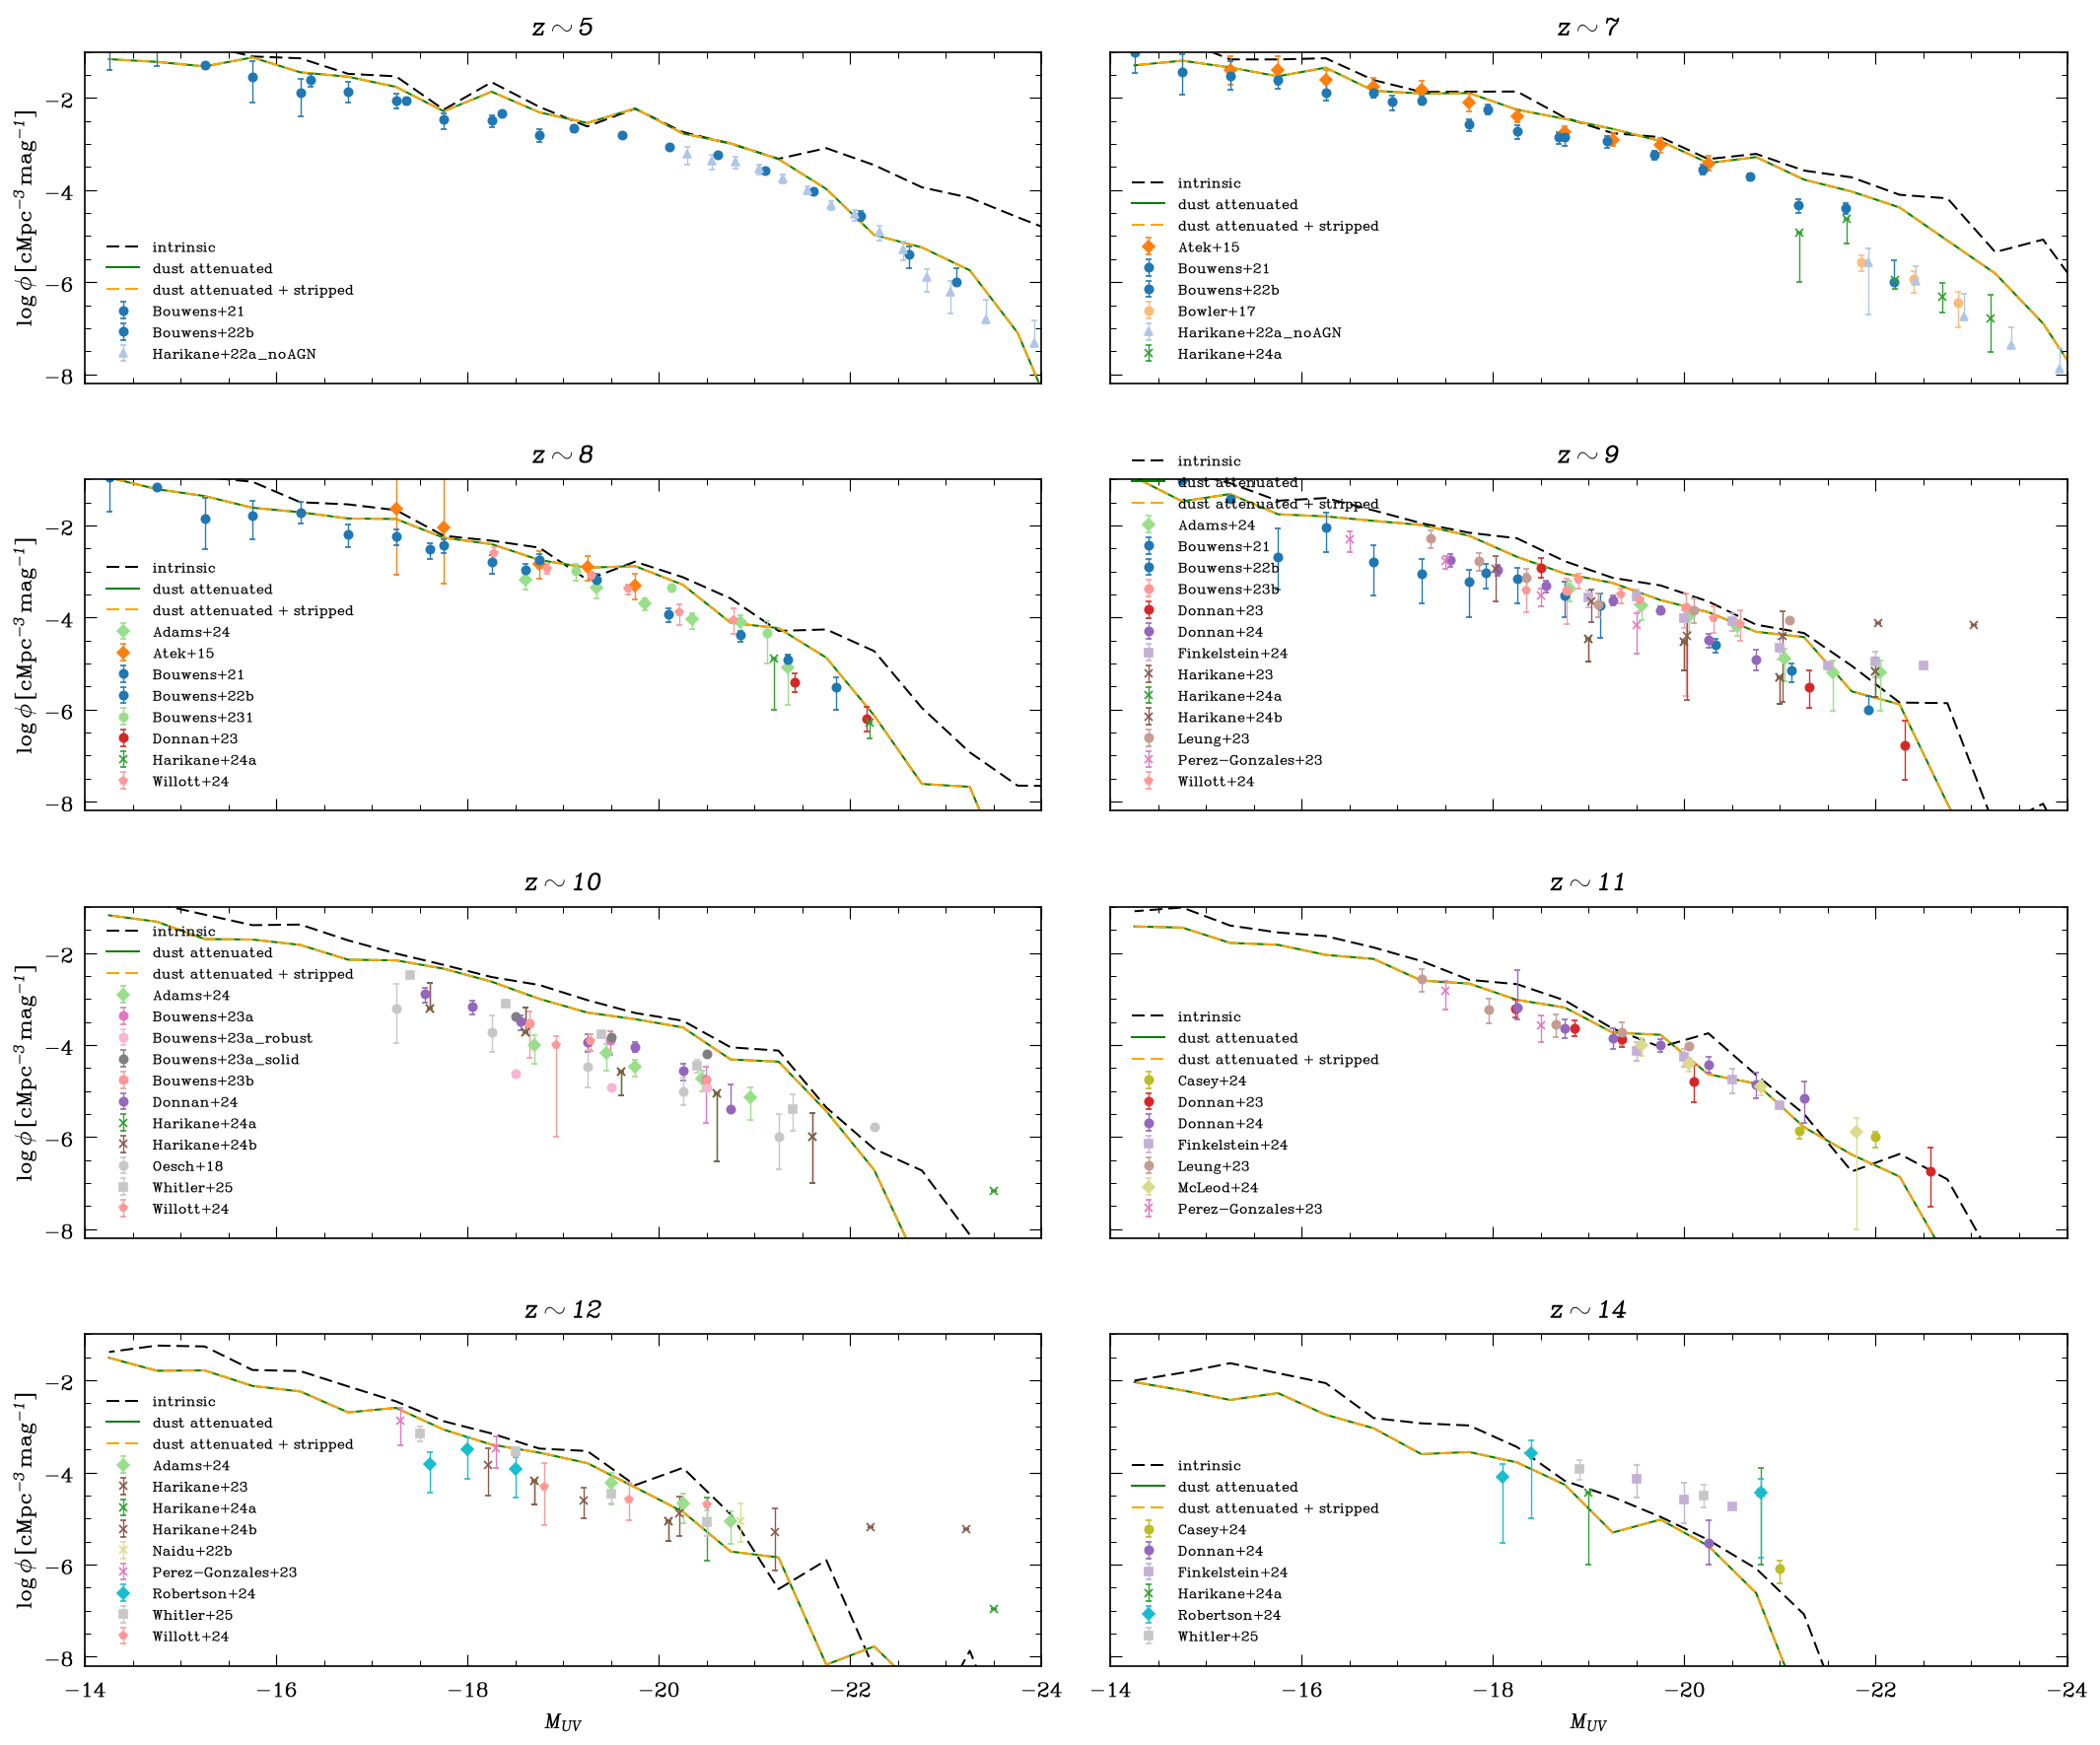

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(18, 15), sharex=True, sharey=True)
for ax, z_i, zt in zip(axes.ravel(), z_use, z_targets):
    ax.plot(centers, np.log10(hist_int[z_i] / dM), "k--", label="intrinsic")
    ax.plot(centers, np.log10(hist_obs[z_i] / dM), "g-", label="dust attenuated")
    ax.plot(centers, np.log10(hist_tot[z_i] / dM), color="orange", ls="--", label="dust attenuated + stripped")
    at_this_z = obs[np.isclose(obs["z"], zt)]
    for source_name, source_rows in at_this_z.groupby("Source"):
        plot_one_survey(ax, source_rows, source_name)
    ax.set_xlim(-14, -24)
    ax.set_ylim(-8.2, -1.0)
    ax.set_title(rf"$z \sim {redshifts[z_i - 1]:.0f}$")
    ax.legend(frameon=False, fontsize=10, loc=3)

for ax in axes[-1, :]:
    ax.set_xlabel(r"$M_{UV}$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\log\phi\,[{\rm cMpc}^{-3}\,{\rm mag}^{-1}]$")
fig.tight_layout()
plt.show()